# Phase 2 – Statistical Process Control (SPC)
I-MR control charts for total cycle time, **S08 (assembly)** and **S09 (conveyor/wait)**, plus process capability.
Control limits are calculated from the first normal period (cycles 1–25); disturbed cycles are removed from the baseline until it is clean.
Input: `outputs/phase1_state_time_table.xlsx` from Phase 1.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = '../outputs'      # relative path: go up one folder (..), then into outputs

table = pd.read_excel(f'{OUT_DIR}/phase1_state_time_table.xlsx', sheet_name='state_times', index_col=0)
print('Cycles loaded:', len(table))
table[['scenario', 'S08', 'S09', 'Total']].head()

Cycles loaded: 92


,scenario,S08,S09,Total
cycle,,,,
1,Normal,68.21,87.12,296.60
2,Normal,69.00,86.60,297.27
3,Normal,68.42,86.02,296.30
4,Normal,68.25,85.26,295.40
5,Normal,68.14,85.15,295.03


In [2]:
D2, D4 = 1.128, 3.267       # standard SPC constants for moving ranges of 2 points

def imr_limits(series, baseline):
    """Control limits from a stable baseline period.
    Points outside the limits are removed and the limits recalculated until the baseline is clean."""
    base = series.loc[baseline]
    while True:
        cl = base.mean()
        mr_bar = base.diff().abs().mean()
        sigma = mr_bar / D2                                   # short-term (within) sigma
        keep = base[(base - cl).abs() <= 3 * sigma]
        if len(keep) == len(base):
            break
        base = keep
    return {'CL': cl, 'sigma': sigma, 'UCL': cl + 3 * sigma, 'LCL': cl - 3 * sigma,
            'MR_bar': mr_bar, 'MR_UCL': D4 * mr_bar, 'baseline_n': len(base)}

def spc_rules(series, lim):
    """Rule 1: point beyond a 3-sigma limit.  Rule 2: 8 or more points in a row on one side of the centre line."""
    rule1 = (series > lim['UCL']) | (series < lim['LCL'])
    side = np.sign(series - lim['CL'])
    run_length = side.groupby((side != side.shift()).cumsum()).transform('size')
    rule2 = (run_length >= 8) & ~rule1
    return rule1, rule2

In [3]:
def imr_chart(series, lim, title, filename):
    rule1, rule2 = spc_rules(series, lim)
    mr = series.diff().abs()
    top = lim['CL'] * 1.06                                     # zoom so the limits stay readable
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    # Individuals chart
    ax1.plot(series.index, series.clip(upper=top), color='#257de0', lw=1.3, marker='o', ms=3, zorder=2)
    ax1.scatter(series.index[rule2], series[rule2].clip(upper=top), color='#f2a600', s=30, zorder=3, label='8+ in a row on one side')
    clipped = series > top
    ax1.scatter(series.index[rule1 & ~clipped], series[rule1 & ~clipped], color='#d03b3b', s=34, zorder=4, label='beyond 3σ limit')
    ax1.scatter(series.index[clipped], [top] * clipped.sum(), marker='^', color='#d03b3b', s=45, zorder=5,
                label=f'beyond limit, above {top:.0f} s (cut off)')
    for name, style in [('UCL', '--'), ('CL', '-'), ('LCL', '--')]:
        ax1.axhline(lim[name], color='#666666', lw=1, ls=style)
        ax1.text(series.index.max() + 1.5, lim[name], f'{name} {lim[name]:.1f}', va='bottom' if name != 'LCL' else 'top', fontsize=8, color='#666666')
    ax1.set_ylabel('Seconds')
    ax1.set_xlim(0, series.index.max() + 9)
    ax1.set_title(title, loc='left', fontsize=11)
    ax1.legend(loc='upper left', fontsize=8, frameon=False)

    # Moving-range chart
    mr_top = lim['MR_UCL'] * 4
    ax2.plot(mr.index, mr.clip(upper=mr_top), color='#257de0', lw=1, marker='o', ms=2.5)
    ax2.axhline(lim['MR_UCL'], color='#666666', lw=1, ls='--')
    ax2.text(series.index.max() + 1.5, lim['MR_UCL'], f"UCL {lim['MR_UCL']:.1f}", va='bottom', fontsize=8, color='#666666')
    ax2.set_ylabel('Moving range (s)')
    ax2.set_ylim(0, mr_top * 1.1)
    ax2.set_xlabel('Cycle')
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{filename}', dpi=110)
    plt.show()
    print(f"{title}: CL {lim['CL']:.2f} s | sigma {lim['sigma']:.2f} s | limits {lim['LCL']:.2f}–{lim['UCL']:.2f} s | "
          f"beyond limits: {rule1.sum()} | runs: {rule2.sum()}")
    return rule1, rule2

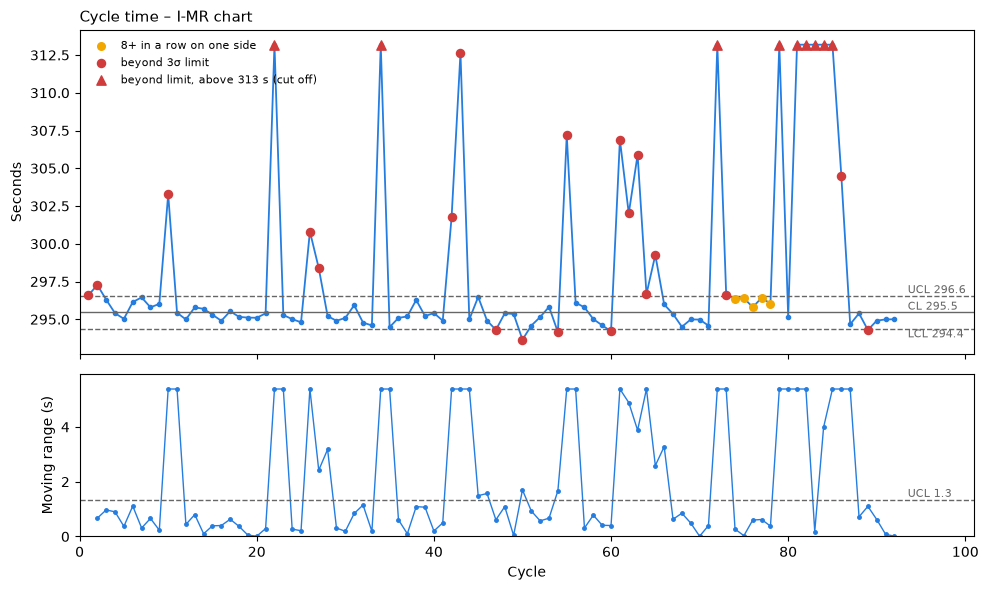

Cycle time – I-MR chart: CL 295.46 s | sigma 0.37 s | limits 294.36–296.55 s | beyond limits: 29 | runs: 5


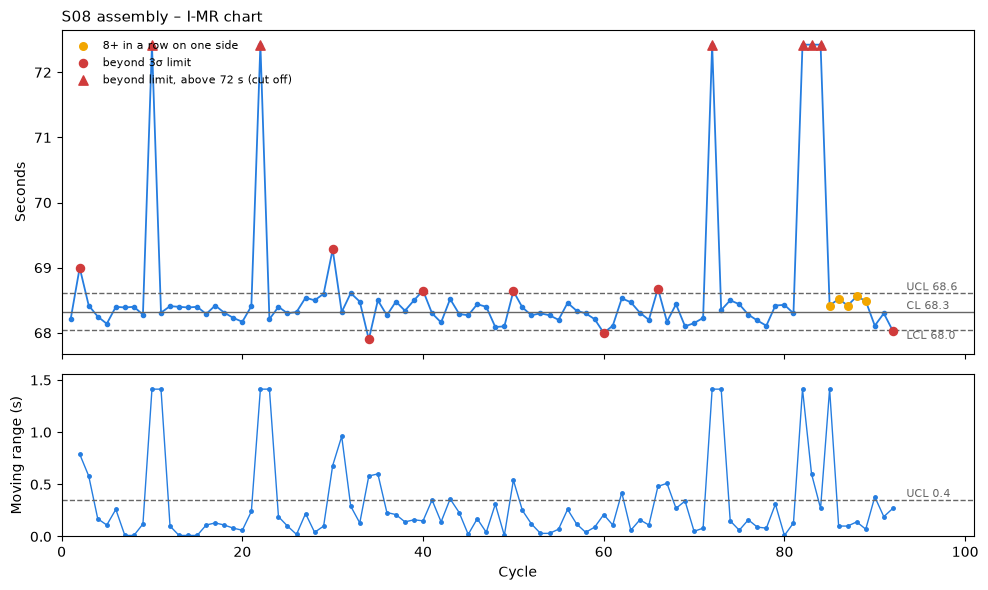

S08 assembly – I-MR chart: CL 68.32 s | sigma 0.10 s | limits 68.04–68.61 s | beyond limits: 14 | runs: 5


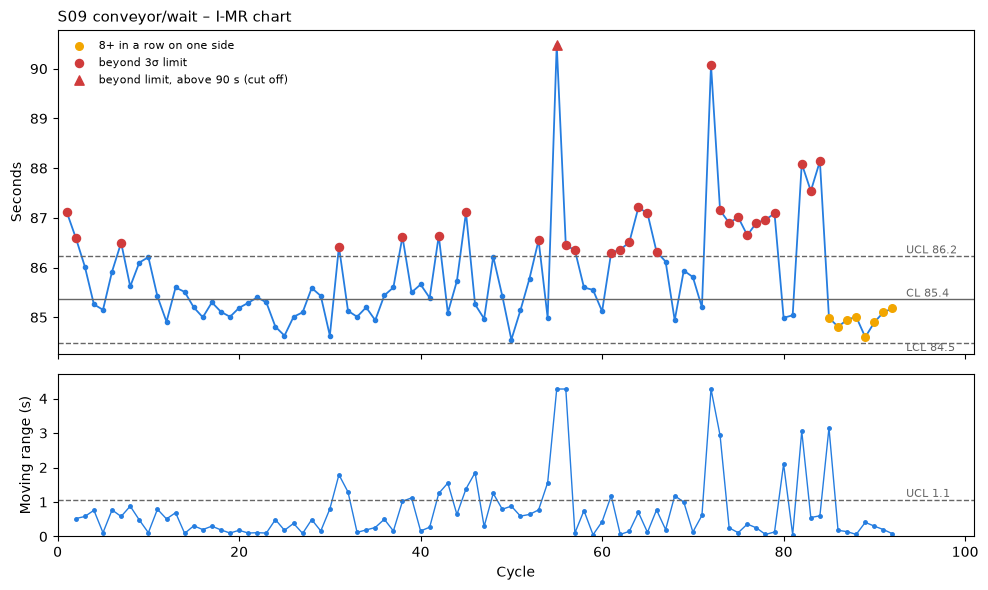

S09 conveyor/wait – I-MR chart: CL 85.36 s | sigma 0.29 s | limits 84.49–86.23 s | beyond limits: 28 | runs: 8


,CL,sigma,LCL,UCL,baseline_n,beyond_limits,run_points
Total,295.457619,0.365248,294.361874,296.553364,21,29,5
S08,68.324545,0.095829,68.037058,68.612033,22,14,5
S09,85.361818,0.29002,84.491757,86.231879,22,28,8


In [4]:
BASELINE = range(1, 26)      # cycles 1-25: first normal period, used to calculate the limits
results = {}
for col, title, fname in [('Total', 'Cycle time – I-MR chart', 'fig5_imr_cycle_time.png'),
                          ('S08', 'S08 assembly – I-MR chart', 'fig6_imr_s08.png'),
                          ('S09', 'S09 conveyor/wait – I-MR chart', 'fig7_imr_s09.png')]:
    lim = imr_limits(table[col], BASELINE)
    rule1, rule2 = imr_chart(table[col], lim, title, fname)
    results[col] = {**lim, 'beyond_limits': int(rule1.sum()), 'run_points': int(rule2.sum()),
                    'beyond_cycles': list(table.index[rule1])}
pd.DataFrame(results).T[['CL', 'sigma', 'LCL', 'UCL', 'baseline_n', 'beyond_limits', 'run_points']].round(2)

In [5]:
USL = 300.0                  # ASSUMED upper spec limit (planned cycle time). The dataset has no spec limits.
ct = table['Total']
lim = results['Total']
cpk = (USL - lim['CL']) / (3 * lim['sigma'])
over = ct > USL
print(f'Assumed USL: {USL:.0f} s')
print(f"Cpk (undisturbed process, short-term sigma {lim['sigma']:.2f} s): {cpk:.2f}")
print(f'Cycles actually above USL: {over.sum()} of {len(ct)} ({over.mean():.0%})')
print('Note: the data is not normal (a few very long cycles), so Cpk only describes the undisturbed process.')

Assumed USL: 300 s
Cpk (undisturbed process, short-term sigma 0.37 s): 4.15
Cycles actually above USL: 18 of 92 (20%)
Note: the data is not normal (a few very long cycles), so Cpk only describes the undisturbed process.


In [6]:
summary = pd.DataFrame(results).T.drop(columns=['beyond_cycles'])
summary.loc['Total', 'USL_assumed'] = USL
summary.loc['Total', 'Cpk'] = round(cpk, 2)
summary.loc['Total', 'cycles_above_USL'] = int(over.sum())
summary.round(3).to_excel(f'{OUT_DIR}/phase2_spc_summary.xlsx')
print('Saved to', OUT_DIR)
summary.round(2)

Saved to ../outputs


,CL,sigma,UCL,LCL,MR_bar,MR_UCL,baseline_n,beyond_limits,run_points,USL_assumed,Cpk,cycles_above_USL
Total,295.457619,0.365248,296.553364,294.361874,0.412,1.346004,21,29,5,300.0,4.15,18.0
S08,68.324545,0.095829,68.612033,68.037058,0.108095,0.353147,22,14,5,NaN,NaN,NaN
S09,85.361818,0.29002,86.231879,84.491757,0.327143,1.068776,22,28,8,NaN,NaN,NaN


## Key findings (Phase 2)
- **The undisturbed process is extremely repeatable:** short-term sigma of cycle time is only **0.37 s** (limits 294.4–296.6 s). Against an assumed target of 300 s, **Cpk = 4.15**.
- **But 18 of 92 cycles (20 %) exceed 300 s.** The problem is not normal variation but **special causes** (disturbances): slow assembly (cycle 22), reduced robot speed (cycles 82–84), and others.
- **S09 (conveyor/wait) drifted:** from about cycle 55 to 84 it ran mostly above its centre line (≈ 1–1.5 s slower), then dropped below the centre line from cycle 85 – a step change not visible in averages. Cause not documented.
- **Recommendation:** focus on detecting and removing disturbances (speed changes, assembly delays), not on reducing normal variation.

*Note: the dataset has no specification limits – the 300 s target is an assumption. Cycle-time data is not normally distributed (a few very long cycles), so Cpk describes only the undisturbed process.*